# 02 · The tensile method: definitions, rules and verification

**Goal.** State how every property of the tensile series is computed: its definition, the formula, the node that computes it, the parameters, the flags and the limits, with each step drawn on three real tests and the whole method checked on synthetic curves with known values. This notebook is the reference for the method; the other notebooks link here.

**Audience.** Materials scientists and engineers (MSE domain experts) who want to judge the numbers. No RDF or workflow knowledge is needed.

**Prerequisites.** The quantities of a tensile test (ReH, ReL, Rp0.2, Rm, Ag, Agt, A, Z) as used in ISO 6892-1. The `pmd-demonstrator` environment, with `ONTODOCKER_ADDRESS` (and `ONTODOCKER_TOKEN` if required) set before Jupyter starts.

**Reading paths.** MSE domain experts: [05](05-tensile-analysis-overview.ipynb) → **02** → [01](01-tensile-data-from-graphs.ipynb) → [06](06-tensile-results-publication.ipynb). Ontologists and RDF experts: [01](01-tensile-data-from-graphs.ipynb) → [04](04-tensile-workflow-knowledge-graph.ipynb) → [05](05-tensile-analysis-overview.ipynb) → [06](06-tensile-results-publication.ipynb). Workflow developers: [03](03-tensile-workflow-building.ipynb) → [04](04-tensile-workflow-knowledge-graph.ipynb) → **02** → [05](05-tensile-analysis-overview.ipynb) → [06](06-tensile-results-publication.ipynb). Readers new to Ontodocker and the Dataportal may start with [00](00-infrastructure-tour.ipynb).

*Execution class: network-read (SPARQL queries to Ontodocker and three curve downloads from the public data host); the verification on synthetic curves is local.*

**The method in one paragraph.** Every property is defined by this method and inspired by ISO 6892-1; the definitions below follow common descriptions of the standard and were not checked against its text, so nothing here claims conformity. The analysis works on the raw samples of force, extensometer strain and crosshead travel, without smoothing. It first finds the samples whose strain is valid, fits a provisional elastic line and a noise level, decides the yield type and the yield strengths from drops of the force, then fits the elastic line in a window tied to the yield point and derives E, the strain origin, Rp0.2, Fm, Rm, Ag and Agt from it. A and Z come from the test record. Each step is one node of the package `pmd_tensile`; undefined values are NaN, and every flag (`<property>:<flag>`) names why.

## Quantities

| Symbol | Meaning | How it is computed here | Unit | Section |
| --- | --- | --- | --- | --- |
| k_ext | end of the valid extensometer strain | first sample from which the strain no longer follows the crosshead | sample | 1 |
| s_n | noise level of the force, as stress | 1.4826 · MAD of the second differences of F in the provisional window, / √6, / S0 | MPa | 2 |
| ReH | upper yield strength | stress at the peak before the first drop of at least 0.5 % (or 5 s_n) | MPa | 3 |
| ReL | lower yield strength | lowest stress on the yield plateau after the initial transient | MPa | 3 |
| E | slope of the elastic line (not a material modulus) | least-squares slope of stress on strain, 10–40 % of the reference stress | GPa | 4 |
| e₀ | strain origin | strain where the elastic line crosses zero stress | % | 4 |
| Rp0.2 | proof strength | stress where the plastic strain e − e₀ − σ/E reaches 0.2 % | MPa | 5 |
| Fm, Rm | maximum force, tensile strength | largest force (after yielding), Rm = Fm/S0 | N, MPa | 6 |
| Agt, Ag | total and plastic extension at Fm | strain at the middle of the near-maximum band, minus e₀ (and minus Rm/E) | % | 6 |
| A, Z | elongation after fracture, reduction of area | from L0, Lu and S0, Su of the test record | % | 7 |
| u(S0)/S0 | relative uncertainty of S0 | scatter of the cross-section measurements | – | 8 |

## Setup

The package `pmd_tensile` is installed by `environment.yml`. The analysis of one curve is a chain of nodes; `analyse_curve` calls them directly in the order of the workflow and returns their values and diagnostics. The second code cell is tagged `parameters` for papermill.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

from pmd_tensile import plotting, profiles, sources
from pmd_tensile.nodes.acquisition import fetch_curve, get_reported_properties, get_specimen_record
from pmd_tensile.nodes.analysis.comparison import compare_with_reported
from pmd_tensile.nodes.analysis.geometry import elongation_after_fracture, reduction_of_area, s0_scatter
from pmd_tensile.orchestration import analyse_curve
from pmd_tensile.parameters import DEFAULT_PARAMETERS

pd.set_option("display.max_colwidth", None)
pd.set_option("display.precision", 4)

In [2]:
profile_id = "pmdco2-tto"
source = {
    "kind": "ontodocker",
    "datasets": [
        "pmdco2_tto_example_parallel",
        "pmdco2_tto_example_perpendicular",
        "pmdco2_tto_example_diagonal",
    ],
}

## The three tests

| Specimen | Orientation | Why it is here |
| --- | --- | --- |
| Zx3 | in rolling direction | the regular case: clear upper yield point, straight elastic part |
| Zy3 | perpendicular to rolling direction | a low-load event in the elastic part, and a dip at the end of the plateau |
| Zd3 | diagonal to rolling direction | a soft spot inside the elastic window |

The acquisition nodes read the record of each test from the graph (S0, the cross-section measurements, L0, Lu, Su, lab notes, curve location) and download its curve into memory; [notebook 01](01-tensile-data-from-graphs.ipynb) shows how. The specimen table of all ten tests only gives every specimen the same colour as in notebook 05.

In [3]:
if source["kind"] == "ontodocker" and not os.getenv(sources.ONTODOCKER_ADDRESS_ENV, "").strip():
    raise RuntimeError("Set ONTODOCKER_ADDRESS (and ONTODOCKER_TOKEN if required) before starting Jupyter.")

ids = ["Zx3", "Zy3", "Zd3"]
specimens = profiles.specimen_table(profile_id, source)
colors = plotting.specimen_colors(dict(zip(specimens["specimen_id"], specimens["orientation"])))

records = {sid: get_specimen_record(profile_id, source, sid) for sid in ids}
reported = {sid: get_reported_properties(profile_id, source, sid) for sid in ids}
curves = {sid: fetch_curve(records[sid]) for sid in ids}
retrieved = pd.Timestamp.now(tz="Europe/Berlin").floor("s")

analyses, a_percent, z_percent, s0_u_rel = {}, {}, {}, {}
for sid, record in records.items():
    curve = curves[sid]
    a_percent[sid], _ = elongation_after_fracture(record.l0_mm, record.lu_mm)
    z_percent[sid], _ = reduction_of_area(record.s0_mm2, record.su_mm2)
    s0_u_rel[sid], _, _ = s0_scatter(record.s0_mm2, record.cross_section_measurements_mm2)
    analyses[sid] = analyse_curve(
        curve.force_n, curve.strain, curve.crosshead_mm, record.s0_mm2, record.l0_mm,
        a_percent=a_percent[sid], rate_switch_strain=record.rate_switch_strain,
    )

display(pd.DataFrame({
    sid: {"S0 / mm²": record.s0_mm2, "L0 / mm": record.l0_mm, "samples": len(curves[sid].force_n),
          "curve": curves[sid].source_url, "SHA-256 (start)": curves[sid].sha256[:16]}
    for sid, record in records.items()
}))
print("data retrieved:", retrieved)

,Zx3,Zy3,Zd3
S0 / mm²,120.396,120.663,120.707
L0 / mm,60.0,60.0,60.0
samples,13134,12110,12257
curve,https://data.pmds-mpcdf-2.pyiron.com/Zx3.csv,https://data.pmds-mpcdf-2.pyiron.com/Zy3.csv,https://data.pmds-mpcdf-2.pyiron.com/Zd3.csv
SHA-256 (start),d0b3aaa7d4e871ec,ad617593ecc08a2e,d4c6535319663a08


data retrieved: 2026-11-10 18:27:43+01:00


## 1. Valid extensometer strain

**Definition.** Extensometers are often removed before fracture; the strain channel then freezes, drops to zero, becomes undefined or stops following the crosshead. Every quantity that needs strain uses only the samples before k_ext.

**Rule** (node `extensometer_validity`). The record is cut into consecutive windows over which the crosshead travels `ext_window_mm` = 0.1 mm. A window is invalid if its strain is not finite, is exactly zero, falls by more than `ext_jump` = 10⁻³ between two samples, or rises by less than `ext_ratio_min` = 0.05 times the crosshead strain (travel / L0). k_ext is the start of the earliest window from which every window to the end is invalid, and at most the first undefined strain after a defined one.

**Flags.** `extensometer:extensometer_ended_early` (largest valid strain below half of A), `extensometer:near_rate_switch`, `extensometer:missing_input`, `extensometer:no_complete_window`.

Panel (a) of the figure in section 3 draws strain against crosshead travel with k_ext marked.

In [4]:
display(pd.DataFrame({
    sid: {"k_ext (sample)": a.k_ext, "largest valid strain / %": 100 * a.max_valid_strain,
          "A / %": a_percent[sid], "flags": "; ".join(a.extensometer.flags)}
    for sid, a in analyses.items()
}).T)

,k_ext (sample),largest valid strain / %,A / %,flags
Zx3,1869,3.8429,35.1667,extensometer:extensometer_ended_early; extensometer:near_rate_switch
Zy3,1966,3.8708,33.5667,extensometer:extensometer_ended_early; extensometer:near_rate_switch
Zd3,2024,4.1968,33.2833,extensometer:extensometer_ended_early; extensometer:near_rate_switch


## 2. Provisional line and noise level

**Why.** The yield search must not depend on the final elastic line, which itself depends on the yield point. It uses a provisional line and a noise level.

**Rule** (node `provisional_elastic_line`). With R = `provisional_fraction_of_rm` · Fmax = 0.5 · Fmax, the provisional line σ = E₀·e + b₀ is the least-squares line through the samples with valid strain on the first loading branch (before the force first reaches R) with force between 0.10 R and 0.40 R. On the same samples the noise level is

  s_F = 1.4826 · median(|Δ²F − median(Δ²F)|) / √6,  s_n = s_F / S0,

with the second differences Δ²F_i = F_{i+1} − 2 F_i + F_{i−1}. For independent noise of standard deviation σ, Var(Δ²F) = 6σ², so s_F estimates σ; a straight trend contributes nothing to Δ²F and a smooth bend almost nothing, so a curved loading part or a seating event does not raise it. With fewer than ten second differences s_n is undefined, and the thresholds below use only their relative terms.

**Limit.** s_n measures sample-to-sample noise. If the force signal is filtered (correlated noise), slower fluctuations are larger than s_n; on these curves the same estimate at a lag of ten samples is 7–43 times s_n, at most 0.11 MPa, and still far below the relative threshold of the drop test (about 2 MPa, section 3).

Panels (b) and (c) of the next figure show the provisional window and line, and the scatter of the samples around the line. That scatter is what version 2 of the method used as its noise level: it contains every bend of the curve, here Zy3's low-load event and Zd3's soft spot.

## 3. Yield type, ReH and ReL

**Upper yield point** (node `yield_points`). Above half of Fmax, the first sample whose force lies at least d = max(`drop_rel` · M, `drop_noise_factor` · s_F) below the running maximum M marks a drop (`drop_rel` = 0.5 %, `drop_noise_factor` = 5). The peak before it is the upper yield point, ReH = F(peak)/S0, the raw sample without smoothing. It counts only if the plastic strain at the peak, e − (σ − b₀)/E₀, is at most `peak_max_plastic_strain` = 0.5 % and grows by at least `min_flow_plastic_strain` = 0.05 % before the force exceeds the peak again. Otherwise the yielding is continuous, ReH and ReL are undefined, and the flags are `reh:no_upper_yield` and `rel:no_upper_yield`; if no drop was found while the extensometer measured, `reh:no_drop_in_valid_strain` says so.

**Lower yield point.** The yield range runs from the peak to the first sample back at ReH (the end of yielding). The plateau level P is the median of its samples in the lower half between their minimum and ReH. A transient begins at the first sample below P − d and ends when the stress is back at P. After it, the lowest sample is the candidate ReL, and the plateau band reaches from it to as far above P. The candidate is ReL if the samples in the band span at least `plateau_min_extent` = 0.2 % of plastic strain; otherwise ReL is the lowest sample before the recovery, flagged `rel:single_minimum`. If the stress never returns to ReH, the range ends at the last sample above half of Fmax (which excludes the fracture), and every result is flagged `fm:no_return_to_reh`.

Panel (d) draws ReH − d over the yield range: a drop below this line marks yielding, and a cross marks the first sample whose drop qualified. The legend gives, per specimen, the largest drop seen while the strain was valid and the required d.

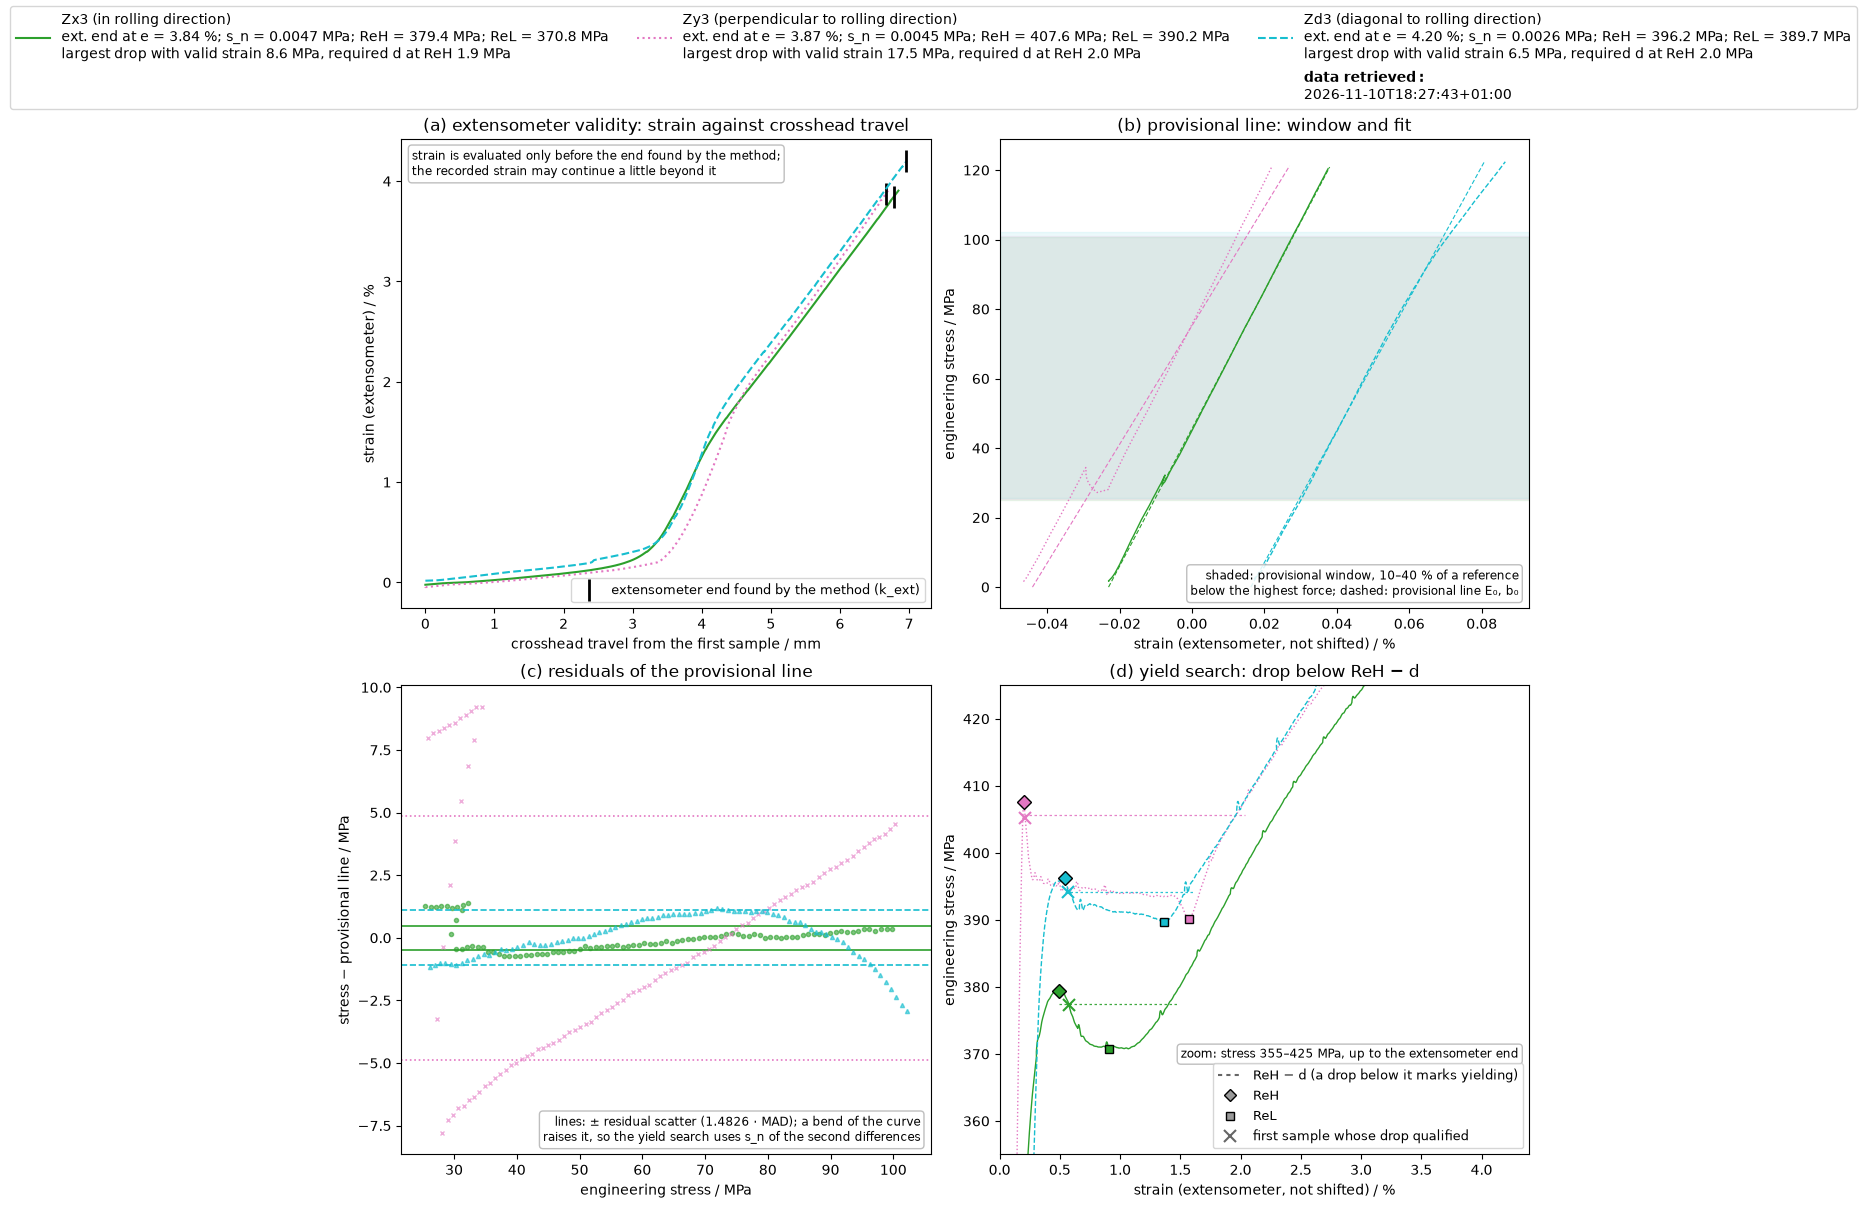

In [5]:
fig = plotting.yield_step_figure(records, curves, analyses, colors=colors, retrieved=retrieved)

In [6]:
display(pd.DataFrame({
    sid: {"yield type": a.yield_type, "ReH / MPa": a.reh_mpa, "ReL / MPa": a.rel_mpa,
          "s_n / MPa": a.noise_mpa, "d at ReH / MPa": a.yielding.drop_threshold_mpa,
          "largest valid drop / MPa": a.yielding.largest_valid_drop_mpa,
          "plateau level P / MPa": a.yielding.plateau_level_mpa,
          "flags": "; ".join(a.yielding.flags)}
    for sid, a in analyses.items()
}).T)

,yield type,ReH / MPa,ReL / MPa,s_n / MPa,d at ReH / MPa,largest valid drop / MPa,plateau level P / MPa,flags
Zx3,discontinuous,379.4088,370.7641,0.0047,1.897,8.6446,371.3601,
Zy3,discontinuous,407.647,390.1871,0.0045,2.0382,17.4599,394.23,rel:single_minimum
Zd3,discontinuous,396.21,389.7225,0.0026,1.981,6.4875,391.1674,


**Zy3.** The plateau declines slowly from about 395 to 392 MPa and then dips to 390.2 MPa at 1.57 % strain before work hardening. The rule treats this dip at the end of the plateau as its transient; since the stress recovers to P only on the work-hardening rise, the plateau after the recovery has no extent, and ReL is the lowest sample before the recovery, with `rel:single_minimum`. The value is the lowest stress during yielding. Under the usual description of ReL (the lowest stress during plastic yielding, disregarding initial transient effects) it is the ReL, provided the dip belongs to plastic yielding and is not an artefact of the test; a value from the plateau alone would lie 2–4 MPa higher, depending on where the dip is taken to begin. The measured strain rate is constant through the dip, so a change of the set rate does not cause it; an interaction of the strain control with the moving Lüders band is not excluded.

## 4. Elastic line, strain origin and E

**Rule** (node `elastic_line`). E and b are the least-squares line σ = E·e + b through the samples with valid strain on the first loading branch with stress between `f_lo` = 10 % and `f_hi` = 40 % of a reference stress. The reference is ReH for discontinuous yielding. For continuous yielding it is the fixed point σ_ref = Rp0.2(E): starting from Rp0.2 with the provisional line, the window is refitted until E changes by less than `window_rel_tol` = 10⁻⁴ (at most `max_window_iterations` = 20 times). At least `min_elastic_points` = 10 samples are needed. The strain origin e₀ = −b/E removes the seating offset of the strain channel.

**E is the slope of the elastic line, not a material modulus**: the extensometer class and its averaging are unknown, and the strain is measured on one side.

**Window sensitivity** (node `window_sensitivity`). The line is refitted for every window of a grid (lower bound 5, 10, 15 %, upper bound 30, 40, 50 % of the reference stress); E, Rp0.2, Ag and Agt are evaluated with each, and the node reports their ranges, never selecting a window. If E changes by more than `e_window_range_max` = 5 % across the grid, the flag `e:window_sensitive` marks it. The 5 % was chosen after seeing these ten tests (the largest unflagged range is 4.1 %, the smallest flagged one 14 %).

Panel (a) shows the window, the elastic line and the offset line on Zx3; panel (b) the residuals of the fit (a straight segment scatters around zero); panel (c) E in every window of the grid, with the lab's E as lines; panel (d) the 0.2 % offset construction.

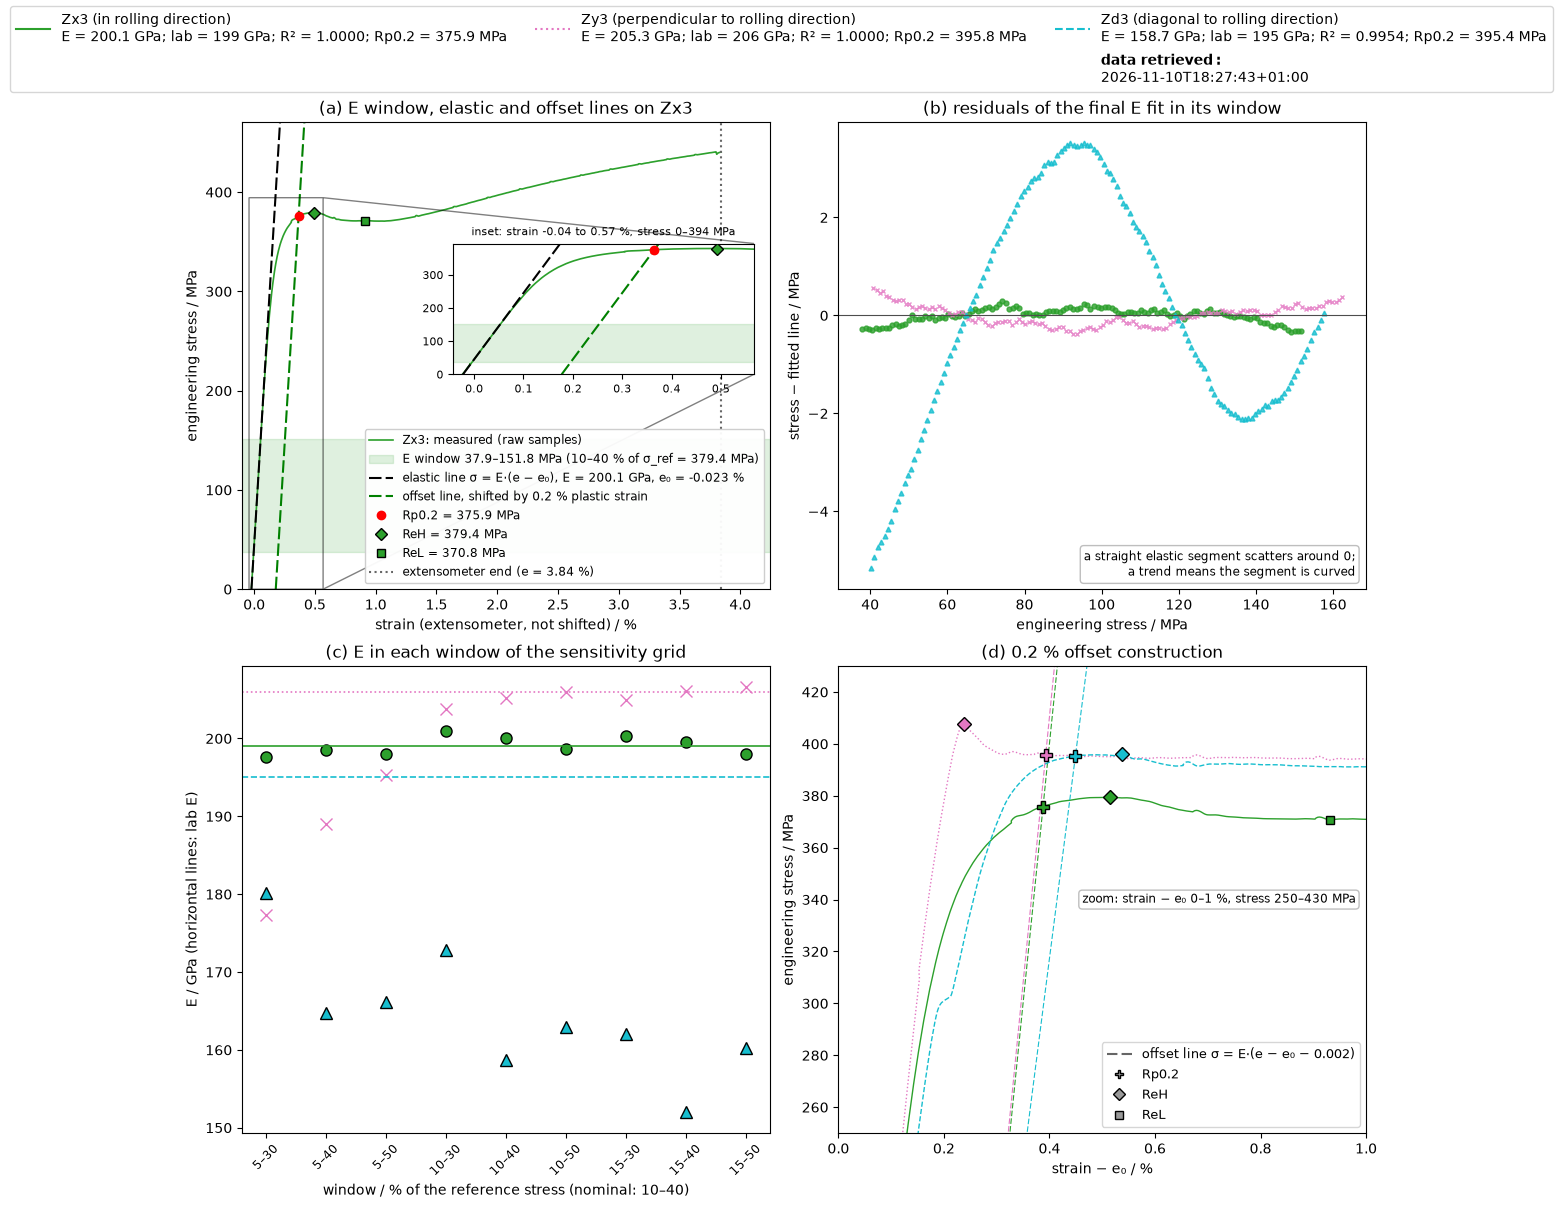

In [7]:
fig = plotting.elastic_step_figure(records, curves, analyses, reported, method_specimen="Zx3", colors=colors,
                                   retrieved=retrieved)

In [8]:
display(pd.DataFrame({
    sid: {"E / GPa": a.e_gpa, "window / MPa": tuple(round(v, 1) for v in a.elastic.window_mpa),
          "samples": a.elastic.n, "R²": a.elastic.r2, "e₀ / %": 100 * a.strain_origin,
          "E over the grid / GPa": (round(a.e_min_gpa, 1), round(a.e_max_gpa, 1)),
          "range / E": (a.e_max_gpa - a.e_min_gpa) / a.e_gpa, "lab E / GPa": reported[sid].e_gpa,
          "flags": "; ".join(a.elastic.flags + a.sensitivity.flags)}
    for sid, a in analyses.items()
}).T)

,E / GPa,window / MPa,samples,R²,e₀ / %,E over the grid / GPa,range / E,lab E / GPa,flags
Zx3,200.0756,"(37.9, 151.8)",132,1.0,-0.0226,"(197.6, 201.0)",0.0169,199.0,
Zy3,205.2504,"(40.8, 163.1)",140,1.0,-0.0369,"(177.3, 206.6)",0.1427,206.0,e:window_sensitive
Zd3,158.6705,"(39.6, 158.5)",138,0.9954,0.009,"(152.0, 180.1)",0.177,195.0,e:window_sensitive


**Zd3** has a soft spot between 20 and 40 % of ReH, inside the window: its slope there is about 150–160 GPa, below and above it about 190–200 GPa. Its E is therefore 158.7 GPa against 195 GPa from the lab, and the flag marks it; the lab's value suggests a different evaluation range, which cannot be checked. **Zy3**'s range comes only from the windows that start at 5 % of ReH, below the low-load event at about 34 MPa; the reported E (10–40 %) is not affected.

## 5. Proof strength Rp0.2

**Rule** (node `proof_strength`). The plastic strain is e_p = e − e₀ − σ/E. Searching the samples with valid strain from the first one at or above the lower bound of the elastic window (so that a curved start below the window cannot cross), Rp0.2 is the stress at the first crossing of e_p = `offset_plastic_strain` = 0.2 %, interpolated linearly between the two samples around it.

**Flags.** `rp02:in_yield_plateau`: for discontinuous yielding the crossing lies in the yield range, where Rp0.2 is not a meaningful property (it is then a plateau stress); `rp02:extensometer_invalid`, `rp02:not_reached`, `rp02:no_elastic_modulus`, `rp02:near_rate_switch`.

In [9]:
display(pd.DataFrame({
    sid: {"Rp0.2 / MPa": a.rp02_mpa, "over the grid / MPa": (round(a.rp02_min_mpa, 2), round(a.rp02_max_mpa, 2)),
          "lab Rp0.2 / MPa": reported[sid].rp02_mpa, "flags": "; ".join(a.proof.flags)}
    for sid, a in analyses.items()
}).T)

,Rp0.2 / MPa,over the grid / MPa,lab Rp0.2 / MPa,flags
Zx3,375.8609,"(375.81, 375.99)",376.0,
Zy3,395.7749,"(395.43, 395.82)",None,rp02:in_yield_plateau
Zd3,395.447,"(394.44, 395.6)",None,


## 6. Maximum force, Rm, Agt and Ag

**Rule** (node `maximum_force`). For continuous yielding Fm is the largest finite force. For discontinuous yielding it is the largest force after the end of yielding, during work hardening, so that an upper yield peak above the later maximum is not taken; without work hardening Fm is undefined (`fm:no_work_hardening`). Rm = Fm/S0.

**Rule** (node `elongation_at_maximum_force`). Near the maximum the force is flat and noisy, so the strain at Fm is the middle of the near-maximum band: the contiguous samples around the maximum with F ≥ Fm (1 − δ), δ = max(`band_rel_min` = 2·10⁻⁴, `band_noise_factor` · s_F / Fm) with `band_noise_factor` = 3. Agt = (e_mid − e₀) · 100 %, Ag = Agt − Rm/E · 100 %.

**On these tests Ag and Agt are undefined**: the valid extensometer strain ends at about 3.8–4.2 %, long before Fm. The figure shows where Fm lies on the crosshead record and where the strain record ends.

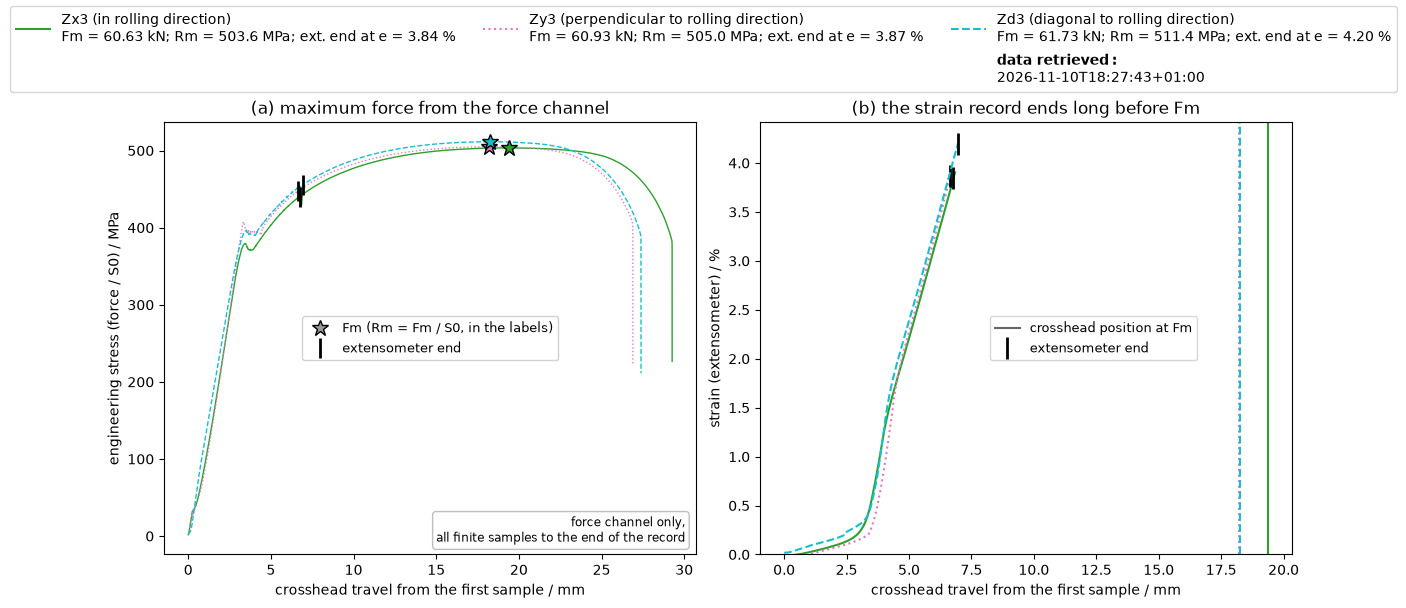

In [10]:
fig = plotting.maximum_force_step_figure(records, curves, analyses, colors=colors, retrieved=retrieved)

In [11]:
display(pd.DataFrame({
    sid: {"Fm / kN": a.fm_n / 1000, "Rm / MPa": a.rm_mpa, "lab Rm / MPa": reported[sid].rm_mpa,
          "Agt / %": a.agt_percent, "Ag / %": a.ag_percent,
          "flags": "; ".join(a.maximum_flags + a.elongation.flags)}
    for sid, a in analyses.items()
}).T)

,Fm / kN,Rm / MPa,lab Rm / MPa,Agt / %,Ag / %,flags
Zx3,60.6278,503.57,504.0,NaN,NaN,ag:extensometer_invalid; agt:extensometer_invalid
Zy3,60.9302,504.9618,505.0,NaN,NaN,ag:extensometer_invalid; agt:extensometer_invalid
Zd3,61.7346,511.442,511.0,NaN,NaN,ag:extensometer_invalid; agt:extensometer_invalid


## 7. A and Z

From the test record (nodes `elongation_after_fracture`, `reduction_of_area`): A = (Lu − L0)/L0 · 100 % and Z = (S0 − Su)/S0 · 100 %. A missing length or area gives NaN with `a:missing_input` or `z:missing_input`.

## 8. Uncertainty components

The method reports components side by side and never combines them:

- **S0 scatter** (node `s0_scatter`): u(S0)/S0 = sd(s₁ … sₙ)/√n / S0 with n − 1 degrees of freedom, the within-specimen scatter of the cross-section measurements. Every stress, and E, carries the same relative uncertainty from S0; strains do not.
- **Standard error of E**: the least-squares standard error of the slope. It is conditional on the window and on independent residuals, which the lag-1 autocorrelation of the residuals shows they are not; it is not an uncertainty.
- **Window ranges** (section 4): a sensitivity, not an uncertainty.

Not included: the classes of the force measuring system and of the extensometer (unknown), calibration, the uncertainty of Lu and Su, the sampling resolution at ReH (reported as the force step at the peak), the bias of a minimum or maximum of noisy samples, rate effects, and the variability of the material (visible only in the statistics per orientation of notebook 05).

In [12]:
display(pd.DataFrame({
    sid: {"u(S0)/S0": s0_u_rel[sid], "SE(E) / GPa": a.elastic.stderr_gpa,
          "lag-1 autocorrelation": a.elastic.lag1_rho, "effective samples": a.elastic.n_eff,
          "force step at ReH / MPa": a.yielding.reh_sample_increment_mpa}
    for sid, a in analyses.items()
}).T)

,u(S0)/S0,SE(E) / GPa,lag-1 autocorrelation,effective samples,force step at ReH / MPa
Zx3,0.0003,0.0763,0.9250,5.1448,0.0150
Zy3,0.0007,0.1009,0.9392,4.3882,0.3911
Zd3,0.0008,0.9230,0.9803,1.3763,0.1437


## 9. Comparison with the lab values

The lab reports Fm, Rm, ReH, Rp0.2, E, A and Z from its own software with unknown settings. The comparison (node `compare_with_reported`) is therefore a consistency check, not a validation: close agreement shows that the two evaluations construct the quantities alike. Each deviation is given in steps of the lab's resolution (1 N, 1 MPa, 1 GPa, 0.5 % for A, 1 % for Z) and in units of the tolerance of the rule (relative 0.1 % for Fm, 0.1 % + 0.5 MPa for Rm, 2 % for ReH and Rp0.2, 10 % for E; for A and Z the deviation may be at most 0.5 percentage points, so that for an integer lab value the computed value rounds to it). ReL has no lab value.

deviation in steps of the lab's resolution,Zd3,Zx3,Zy3
quantity,,,
a_percent,0.5667,0.3333,0.1333
e_gpa,-36.3295,1.0756,-0.7496
fm_n,53.6300,-52.1900,-4.8000
reh_mpa,0.2100,0.4088,-0.3530
rm_mpa,0.4420,-0.4300,-0.0382
rp02_mpa,NaN,-0.1391,NaN
z_percent,-0.3889,0.0534,0.2598


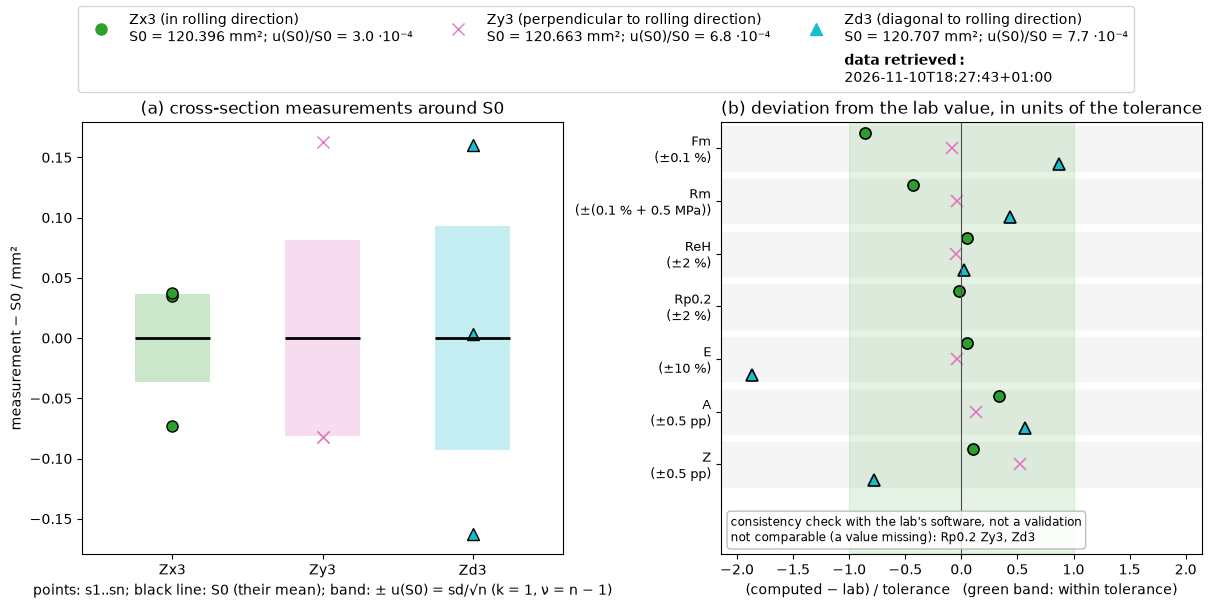

In [13]:
comparison = pd.concat(
    [compare_with_reported(a.fm_n, a.rm_mpa, a.reh_mpa, a.rp02_mpa, a.e_gpa, a_percent[sid], z_percent[sid],
                           reported[sid]).assign(specimen_id=sid)
     for sid, a in analyses.items()],
    ignore_index=True,
)
display(comparison.pivot(index="quantity", columns="specimen_id", values="deviation_in_resolution")
        .rename_axis(columns="deviation in steps of the lab's resolution"))
fig = plotting.lab_comparison_step_figure(records, s0_u_rel, comparison, colors=colors, retrieved=retrieved)

**Fm.** The computed Fm differs from the lab's by up to about 50 N, that is about 50 steps of the lab's 1 N, while ReH, Rp0.2, Rm and E differ by about one step or less (except Zd3's E, section 4). The lab's values themselves suggest why: its Fm divided by S0 gives its Rm to within 0.01 MPa (table below), which a value of Fm read from the curve would almost never do. The lab's Fm therefore appears to be computed back from its Rm rounded to 1 MPa, so its effective step is S0 · 1 MPa, about 120 N, and deviations up to about 60 N are rounding. This is an inference from the reported numbers; the lab's software settings are unknown.

In [14]:
display(pd.DataFrame({
    sid: {"lab Fm / N": reported[sid].fm_n, "lab Fm / S0 / MPa": reported[sid].fm_n / record.s0_mm2,
          "lab Rm / MPa": reported[sid].rm_mpa, "Fm − lab Fm / N": analyses[sid].fm_n - reported[sid].fm_n,
          "S0 · 0.5 MPa / N": 0.5 * record.s0_mm2}
    for sid, record in records.items()
}).T)

,lab Fm / N,lab Fm / S0 / MPa,lab Rm / MPa,Fm − lab Fm / N,S0 · 0.5 MPa / N
Zx3,60680.0,504.0035,504.0,-52.19,60.1980
Zy3,60935.0,505.0015,505.0,-4.80,60.3315
Zd3,61681.0,510.9977,511.0,53.63,60.3535


## 10. Verification on synthetic curves

The generator of the test suite (`tests/synthetic.py`) builds curves from a noise-free stress and a plastic strain per sample, with known values written down before any analysis: an exactly linear elastic part with E = 205 GPa, a sampled upper yield peak at 400 MPa, a plateau at 380 MPa with serrations, Voce work hardening to Rm = 510 MPa; and continuous yielding of the Ramberg-Osgood type. The table compares the method with these values; the offline test suite checks them, with noise, in many more cases.

In [15]:
sys.path.insert(0, str(Path.cwd().parent / "tests"))
import synthetic as sy

cases = {"discontinuous (case a)": sy.reference_a(), "continuous, n = 15": sy.ramberg_osgood(15),
         "continuous, n = 5 (curved)": sy.ramberg_osgood(5)}
rows = {}
for label, c in cases.items():
    r = analyse_curve(*c.args())
    t = c.truth
    rows[label] = {"yield type (true)": t.yield_type, "yield type": r.yield_type,
                   "E true / GPa": t.e_gpa, "E / GPa": r.e_gpa, "ReH true / MPa": t.reh_mpa, "ReH / MPa": r.reh_mpa,
                   "Rp0.2 true / MPa": t.rp02_mpa, "Rp0.2 / MPa": r.rp02_mpa,
                   "Rm true / MPa": t.rm_mpa, "Rm / MPa": r.rm_mpa, "flags": "; ".join(r.flags)}
display(pd.DataFrame(rows).T)

,yield type (true),yield type,E true / GPa,E / GPa,ReH true / MPa,ReH / MPa,Rp0.2 true / MPa,Rp0.2 / MPa,Rm true / MPa,Rm / MPa,flags
discontinuous (case a),discontinuous,discontinuous,205.0,205.0,400.0,400.0,380.0,380.0,510.0,510.0,rp02:in_yield_plateau
"continuous, n = 15",continuous,continuous,204.9996,204.9996,NaN,NaN,300.0,299.9986,480.0,480.0,reh:no_upper_yield; rel:no_upper_yield
"continuous, n = 5 (curved)",continuous,continuous,197.3273,197.3273,NaN,NaN,301.4114,301.4111,480.0,480.0,reh:no_upper_yield; rel:no_upper_yield; e:window_sensitive


With noise of 0.5 MPa on the reference case, 20 seeds:

In [16]:
base = sy.reference_a()
results = [analyse_curve(*sy.noisy(base, seed).args()) for seed in range(20)]
display(pd.DataFrame({
    name: {"true": getattr(base.truth, name), "largest |error|": max(abs(getattr(r, name) - getattr(base.truth, name))
                                                                   for r in results)}
    for name in ("e_gpa", "reh_mpa", "rel_mpa", "rp02_mpa", "rm_mpa")
}).T)
print("yield type discontinuous in", sum(r.yield_type == "discontinuous" for r in results), "of", len(results), "seeds")

,true,largest |error|
e_gpa,205.0,0.9905
reh_mpa,400.0,0.9647
rel_mpa,379.0,1.6124
rp02_mpa,380.0,0.8568
rm_mpa,510.0,1.7349


yield type discontinuous in 20 of 20 seeds


The continuous curve with n = 5 bends so early that E depends on the window by about 9 %; the method reports E = 197.3 GPa against the true 205 GPa and flags `e:window_sensitive`. This is the case the flag exists for.

## 11. Limitations

This is the one place where the limits of the method are stated; the other notebooks link here.

| Limitation | Consequence | Where it matters |
| --- | --- | --- |
| Definitions not checked against the text of ISO 6892-1 | no claim of conformity; E is not an Annex-G modulus | all quantities |
| Lab values from unknown software settings | the comparison is a consistency check, not a validation | section 9 |
| Valid strain ends before Fm | Ag and Agt are undefined | all ten tests |
| A strain channel continued from the crosshead after removal of the extensometer cannot be detected | strain beyond the extensometer could be taken as valid | section 1 |
| The noise level assumes uncorrelated noise | slower fluctuations are larger than s_n | section 2; without effect on these tests |
| Only the first qualifying drop is examined | a dip of 0.5 % above half of Fmax before the real yield drop (grip slip, a hold, a rate change) is examined first and can lead to continuous yielding | not seen on these tests |
| A long noisy plateau without an upper peak can be taken for discontinuous yielding | spurious ReH: about 65 % of runs on the synthetic plateau at 0.5 MPa noise | not seen on these tests (noise about 0.005 MPa) |
| ReL on a smoothly rising plateau, and ReL at a dip at the end of the plateau, are the lowest sample, not a plateau value (`rel:single_minimum`) | ReL depends on where the dip is taken to begin | Zy3 |
| The branch without return to ReH is corrupted by a gradual force decline after the plateau | every result of that branch is flagged `fm:no_return_to_reh` | not reached by these tests |
| E depends on the window when the elastic part is not straight | flagged above 5 % (`e:window_sensitive`), threshold chosen after seeing the data | Zd3, Zy3 |
| A rate change near an evaluation point affects the value | flagged `near_rate_switch` within 0.2 % strain of the switch; Zx1's step at its switch (1.6 %) lies just outside | Zx1 |

## 12. What changed in method version 3

Version 2 was used for the first evaluation of these tests. After that run, three rules were changed, prompted by Zy3, for which version 2 found no upper yield point:

- **Noise level.** Version 2 took s_n from the scatter around the provisional straight line. That scatter contains every bend of the loading curve and, on the synthetic curves, the strain noise times the slope; on Zy3 a low-load event raised it to 4.9 MPa, the required drop to 24 MPa, and the yield drop of 17 MPa was missed. Version 3 estimates s_n from the second differences of the force (section 2). On the ten tests this changes only Zy3, which now shows its upper yield point (ReH 407.65 MPa; the lab reports 408 MPa). Because the change was made after seeing this comparison, the agreement for Zy3 is not independent evidence; the reason for the change is the mechanism above, and it was verified on synthetic curves before it was applied.
- **Window sensitivity.** The flag `e:window_sensitive` is new (section 4); it marks Zd3 and Zy3.
- **Cause of a missing drop.** When no drop is found while the extensometer measures, the flag `reh:no_drop_in_valid_strain` says so; version 2 named the extensometer as the cause.

Every other value of the ten tests is unchanged. The factor of the noise term stays 5; with the lower noise level the rate of spurious yield points on a long noisy plateau rose from 44 to 65 % at 0.5 MPa (section 11).

## Summary

- Every property is a chain of explicit rules on the raw samples, each a node with its parameters and flags; nothing is smoothed and nothing claims conformity with ISO 6892-1.
- On these tests the extensometer ends before Fm, so Ag and Agt are undefined; E is the slope of the elastic line, flagged where it depends on the window.
- The synthetic curves reproduce their declared values within the tolerances of the test suite.

Next: [notebook 05](05-tensile-analysis-overview.ipynb) applies the method to all ten tests; [notebook 01](01-tensile-data-from-graphs.ipynb) shows where the data come from; [notebook 06](06-tensile-results-publication.ipynb) publishes the results.